# Chapter 7 · Product measures and random vectors: interactive demos

Companion to Chapter 7 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/07-product-measures.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.product import (comonotone_table, cdf_independence_defect, covariance,
                               empirical_cdf_defect, fubini_counterexample, fubini_inner_exact,
                               independence_defect, inner_integrals, iterated_integral, marginals,
                               midpoints, product_measure, sample_pair, table_rank)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. One pair of marginals, many joint laws

On a finite space the product measure $\mu_1\otimes\mu_2$ is the outer product of the two mass vectors
(Theorem 7.7), and $X\perp\!\!\!\perp Y$ exactly when the joint table equals the product of its marginals
(Proposition 7.16), that is, when the table has rank one. Here $X\sim B(n,p)$ and $Y\sim B(n',p')$, and the joint
table is $(1-\theta)\,f_X\otimes f_Y+\theta\,C$, where $C$ is the *comonotone* table of $(F_X^{-1}(U),F_Y^{-1}(U))$ for a
single uniform $U$. Every $\theta$ gives the same marginals; only $\theta=0$ gives independence. The joint law is not
determined by the marginal laws.

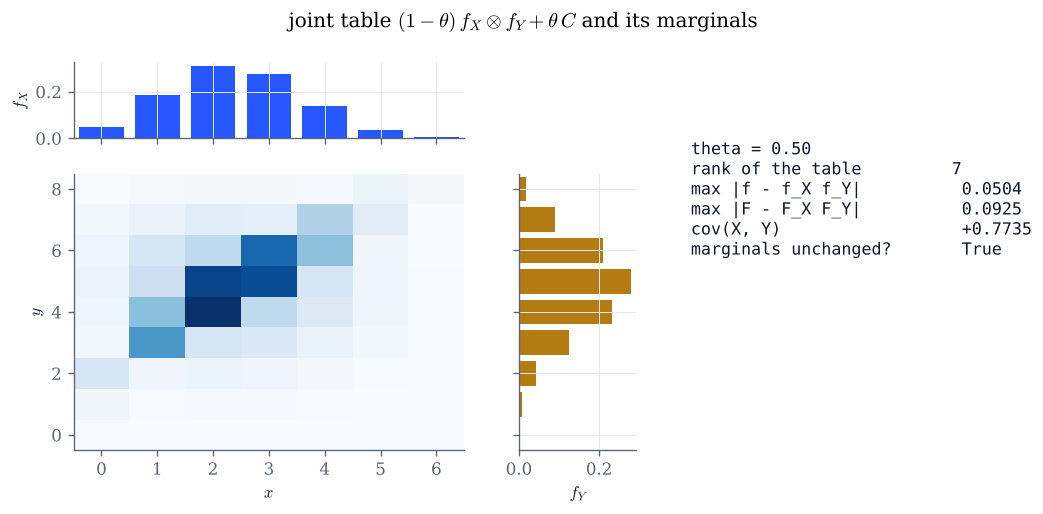

In [2]:
def table_demo(theta=0.5, n=6, p=0.4, n2=8, p2=0.6):
    fx = stats.binom.pmf(np.arange(n + 1), n, p)
    fy = stats.binom.pmf(np.arange(n2 + 1), n2, p2)
    f = (1 - theta) * product_measure(fx, fy) + theta * comonotone_table(fx, fy)
    xs, ys = np.arange(n + 1), np.arange(n2 + 1)
    gx, gy = marginals(f)
    fig = plt.figure(figsize=(10, 4.2))
    gs = fig.add_gridspec(2, 3, width_ratios=[4, 1.2, 3.2], height_ratios=[1.1, 4])
    ax = fig.add_subplot(gs[1, 0])
    ax.imshow(f.T, origin="lower", cmap="Blues", aspect="auto", extent=(-0.5, n + 0.5, -0.5, n2 + 0.5))
    ax.set(xlabel="$x$", ylabel="$y$")
    ax.grid(False)
    top = fig.add_subplot(gs[0, 0], sharex=ax)
    top.bar(xs, gx, color=COBALT, width=0.8)
    top.set(ylabel="$f_X$")
    top.tick_params(labelbottom=False)
    right = fig.add_subplot(gs[1, 1], sharey=ax)
    right.barh(ys, gy, color=GOLD, height=0.8)
    right.set(xlabel="$f_Y$")
    right.tick_params(labelleft=False)
    txt = fig.add_subplot(gs[:, 2])
    txt.axis("off")
    lines = [f"theta = {theta:.2f}",
             f"rank of the table         {table_rank(f)}",
             f"max |f - f_X f_Y|          {independence_defect(f):.4f}",
             f"max |F - F_X F_Y|          {cdf_independence_defect(f):.4f}",
             f"cov(X, Y)                  {covariance(f, xs, ys):+.4f}",
             f"marginals unchanged?       {np.allclose(gx, fx) and np.allclose(gy, fy)}"]
    txt.text(0.0, 0.8, "\n".join(lines), family="monospace", fontsize=10, va="top", color=INK)
    fig.suptitle("joint table $(1-\\theta)\\,f_X\\otimes f_Y+\\theta\\,C$ and its marginals")
    plt.show()

table_demo()

In [3]:
# Explore: theta = 0 is the product measure (rank 1, defects 0); any theta > 0 is dependent.
interact(table_demo,
         theta=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, continuous_update=False, description="theta"),
         n=IntSlider(value=6, min=1, max=15, continuous_update=False, description="n"),
         p=FloatSlider(value=0.4, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p"),
         n2=IntSlider(value=8, min=1, max=15, continuous_update=False, description="n'"),
         p2=FloatSlider(value=0.6, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p'"));

## 2. Two iterated integrals that differ

For $f(x,y)=\dfrac{x^2-y^2}{(x^2+y^2)^2}$ on $(0,1]^2$ the inner integrals are $\int_0^1f(x,y)\,dy=\frac1{1+x^2}$ and
$\int_0^1f(x,y)\,dx=-\frac1{1+y^2}$, so the iterated integrals are $\pm\frac\pi4$; $f$ is not integrable, and Fubini's
theorem does not apply (Remark 7.21). The midpoint rule below uses $n$ outer points and $kn$ inner points. Left: the inner
sums at the outer nodes (dots) against the exact inner integrals (lines). With $k=1$ both orders compute the same finite
double sum, which is $0$: the inner sums at the first outer nodes are far off (note the symmetric logarithmic scale),
and they cancel the rest. The iterated integrals only appear when the inner integral is resolved first.

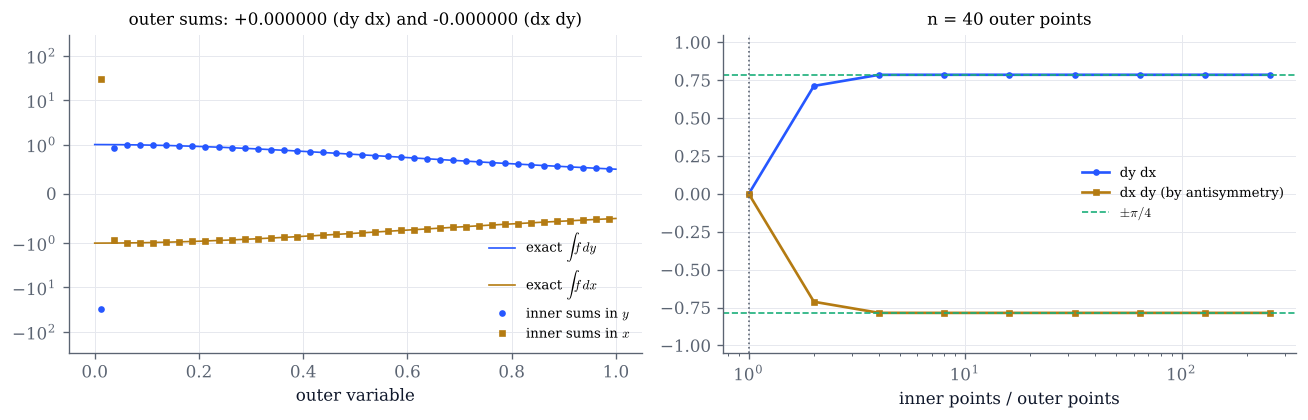

In [4]:
def fubini_demo(n=40, k=1):
    f = fubini_counterexample
    t = midpoints(0, 1, n)
    in_y = inner_integrals(f, t, (0, 1), n * k, "y")
    in_x = inner_integrals(f, t, (0, 1), n * k, "x")
    a, b = in_y.mean(), in_x.mean()
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    s = np.linspace(0, 1, 300)
    ax.plot(s, fubini_inner_exact(s, "y"), color=COBALT, lw=1, label="exact $\\int f\\,dy$")
    ax.plot(s, fubini_inner_exact(s, "x"), color=GOLD, lw=1, label="exact $\\int f\\,dx$")
    ax.plot(t, in_y, "o", color=COBALT, ms=3, label="inner sums in $y$")
    ax.plot(t, in_x, "s", color=GOLD, ms=3, label="inner sums in $x$")
    ax.set_yscale("symlog", linthresh=1)
    ax.set(ylim=(-300, 300), xlabel="outer variable",
           title=f"outer sums: {a:+.6f} (dy dx) and {b:+.6f} (dx dy)")
    ax.legend(fontsize=8, loc="lower right")
    ks = 2 ** np.arange(0, 9)
    vals = [iterated_integral(f, (0, 1), (0, 1), n, n * kk, "dy dx") for kk in ks]
    ax2.plot(ks, vals, color=COBALT, marker="o", ms=3, label="dy dx")
    ax2.plot(ks, [-v for v in vals], color=GOLD, marker="s", ms=3, label="dx dy (by antisymmetry)")
    ax2.axhline(math.pi / 4, color=GREEN, ls="--", lw=1, label="$\\pm\\pi/4$")
    ax2.axhline(-math.pi / 4, color=GREEN, ls="--", lw=1)
    ax2.axvline(k, color=GREY, ls=":", lw=1)
    ax2.set(xscale="log", xlabel="inner points / outer points", ylim=(-1.05, 1.05), title=f"n = {n} outer points")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

fubini_demo()

In [5]:
# Explore: with k = 1 the first inner sums are far from the curves; increase k and watch them join.
interact(fubini_demo,
         n=IntSlider(value=40, min=5, max=400, step=5, continuous_update=False, description="n outer"),
         k=Dropdown(options=[1, 2, 4, 8, 16, 64, 256], value=1, description="k"));

## 3. Uncorrelated is not independent

If $X,Y\in L^1$ are independent, then $\mathbb E[XY]=\mathbb E[X]\,\mathbb E[Y]$ (Proposition 7.26); the converse fails.
For each pair, the left panel shows samples, the centre panel the running estimate of
$\operatorname{cov}(X,Y)=\mathbb E[XY]-\mathbb E[X]\mathbb E[Y]$ with an asymptotic 95% band, and the right panel the largest gap
$|F_{(X,Y)}-F_XF_Y|$ over a grid of sample quantiles: it tends to $0$ for independent pairs (Remark 7.15), so a positive limit proves dependence.
The pair `gamma-mix` has the joint density $x\,e^{-x(1+y)}$ (Exercise 7.8): there $\mathbb E[Y]=+\infty$, and the sample
covariance does not settle.

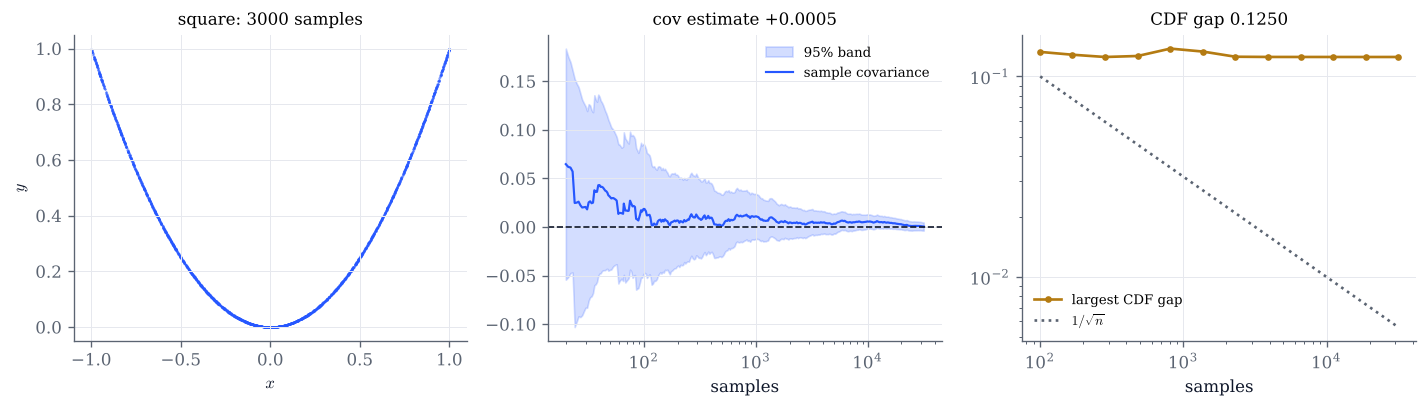

In [6]:
def pair_demo(pair="square", log10_n=4.5, seed=2026):
    n = int(10 ** log10_n)
    x, y = sample_pair(pair, n, seed)
    N = np.arange(1, n + 1)
    mx, my, mxy = np.cumsum(x) / N, np.cumsum(y) / N, np.cumsum(x * y) / N
    cov = mxy - mx * my
    se = np.sqrt(np.maximum(np.cumsum((x * y) ** 2) / N - mxy ** 2, 0) / N)
    k = np.unique(np.geomspace(20, n, 300).astype(int)) - 1
    sizes = np.unique(np.geomspace(100, n, 12).astype(int))
    gaps = [empirical_cdf_defect(x[:m], y[:m]) for m in sizes]
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(12, 3.5))
    m = min(n, 3000)
    a1.scatter(x[:m], y[:m], s=2, color=COBALT, alpha=0.5, lw=0)
    if pair == "gamma-mix":
        a1.set(xlim=(0, np.quantile(x, 0.99)), ylim=(0, np.quantile(y, 0.95)))
    a1.set(title=f"{pair}: {m} samples", xlabel="$x$", ylabel="$y$")
    a2.fill_between(N[k], cov[k] - 1.96 * se[k], cov[k] + 1.96 * se[k], color=COBALT, alpha=0.2, label="95% band")
    a2.plot(N[k], cov[k], color=COBALT, lw=1.3, label="sample covariance")
    a2.axhline(0, color=INK, ls="--", lw=1)
    a2.set(xscale="log", xlabel="samples", title=f"cov estimate {cov[-1]:+.4f}")
    a2.legend(fontsize=8)
    a3.plot(sizes, gaps, color=GOLD, marker="o", ms=3, label="largest CDF gap")
    a3.plot(sizes, 1 / np.sqrt(sizes), color=GREY, ls=":", label="$1/\\sqrt{n}$")
    a3.set(xscale="log", yscale="log", xlabel="samples", title=f"CDF gap {gaps[-1]:.4f}")
    a3.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

pair_demo()

In [7]:
interact(pair_demo,
         pair=Dropdown(options=["independent", "square", "circle", "disk", "gamma-mix"], value="square", description="pair"),
         log10_n=FloatSlider(value=4.5, min=2.5, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\theta=0$ and check that the rank is 1. Is there a $\theta>0$ for which the covariance is $0$? Is the table then a product?
- In section 1, take $n=1$ and $n'=1$ (two Bernoulli variables). Show by hand that for $2\times2$ tables, $\operatorname{cov}(X,Y)=0$ already implies independence.
- In section 2, fix $k=4$ and increase $n$. Does the result move towards $\pi/4$? What matters, $n$ or $k$?
- In section 3, compare the CDF gap of `independent` with the line $1/\sqrt n$, and the gap of `square` with $1/8$.
- In section 3, for `gamma-mix`, replace the pair $(X,Y)$ by $(X,XY)$ in the code: what happens to the CDF gap, and why (Exercise 7.8)?